 Load Libraries

In [40]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn as sk ## ML
import seaborn as sns ## Visualtions
%matplotlib inline

Importing Data

In [41]:
%pip install openpyxl

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.




[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\user\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [42]:
Df = pd.read_excel(r"C:\Users\user\Desktop\PYTHON PROJECTS\Supply chain data.xlsx")


In [43]:
Df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Name,Product Price,Product Status,Shipping Mode
0,DEBIT,3,4,91.25,314.64,Advance shipping,0,73,Sporting Goods,Caguas,...,Java Occidental,COMPLETE,NaN,1360,73,NaN,Smart watch,327.75,0,Standard Class
1,TRANSFER,5,4,-249.09,311.36,Late delivery,1,73,Sporting Goods,Caguas,...,Rajastán,PENDING,NaN,1360,73,NaN,Smart watch,327.75,0,Standard Class
2,CASH,4,4,-247.78,309.72,Shipping on time,0,73,Sporting Goods,San Jose,...,Rajastán,CLOSED,NaN,1360,73,NaN,Smart watch,327.75,0,Standard Class
3,DEBIT,3,4,22.86,304.81,Advance shipping,0,73,Sporting Goods,Los Angeles,...,Queensland,COMPLETE,NaN,1360,73,NaN,Smart watch,327.75,0,Standard Class
4,PAYMENT,2,4,134.21,298.25,Advance shipping,0,73,Sporting Goods,Caguas,...,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,Smart watch,327.75,0,Standard Class


In [44]:
pd.set_option('display.max_rows',101)   ### For maximum Display of Rows and Columns

pd.set_option('display.max_columns',28)

EXPLORATORY DATA ANALYSIS

In [45]:
Df.isna().sum()

Type                               0
Days for shipping (real)           0
Days for shipment (scheduled)      0
Benefit per order                  0
Sales per customer                 0
Delivery Status                    0
Late_delivery_risk                 0
Category Id                        0
Category Name                      0
Customer City                      0
Customer Segment                   0
Customer State                     0
Customer Zipcode                   0
Department Id                      0
Department Name                    0
Latitude                           0
Longitude                          0
Market                             0
Order City                         0
Order Country                      0
Order Customer Id                  0
Order Id                           0
Order Item Cardprod Id             0
Order Item Discount                0
Order Item Discount Rate           0
Order Item Id                      0
Order Item Product Price           0
O

In [46]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Investigate missing values
missing_values = Df.isnull().sum()
missing_values

Type                               0
Days for shipping (real)           0
Days for shipment (scheduled)      0
Benefit per order                  0
Sales per customer                 0
Delivery Status                    0
Late_delivery_risk                 0
Category Id                        0
Category Name                      0
Customer City                      0
Customer Segment                   0
Customer State                     0
Customer Zipcode                   0
Department Id                      0
Department Name                    0
Latitude                           0
Longitude                          0
Market                             0
Order City                         0
Order Country                      0
Order Customer Id                  0
Order Id                           0
Order Item Cardprod Id             0
Order Item Discount                0
Order Item Discount Rate           0
Order Item Id                      0
Order Item Product Price           0
O

In [47]:
miss = (Df.isna().mean()*100).sort_values(ascending=False)
miss[miss>0]

Product Description   100.00
Order Zipcode          95.74
dtype: float64

In [48]:
Df.shape[0]

399

In [49]:
Df.shape

(399, 43)

In [50]:
 Df.isna().sum().sum()

np.int64(781)

In [51]:
Df.notna().sum()

Type                             399
Days for shipping (real)         399
Days for shipment (scheduled)    399
Benefit per order                399
Sales per customer               399
Delivery Status                  399
Late_delivery_risk               399
Category Id                      399
Category Name                    399
Customer City                    399
Customer Segment                 399
Customer State                   399
Customer Zipcode                 399
Department Id                    399
Department Name                  399
Latitude                         399
Longitude                        399
Market                           399
Order City                       399
Order Country                    399
Order Customer Id                399
Order Id                         399
Order Item Cardprod Id           399
Order Item Discount              399
Order Item Discount Rate         399
Order Item Id                    399
Order Item Product Price         399
O

In [52]:
#compute descriptive statistics for each numerical column in the

pd.set_option('display.float_format',lambda x: '%.2f' % x)
##Sets pandas to display floating-point numbers to 2 decimal places instead of long decimals.

#  DataFrame and then transpose the result
Df.describe().transpose()
##Summarises numerical columns and displays each column as a row.

,count,mean,std,min,25%,50%,75%,max
Days for shipping (real),399.00,3.86,1.48,0.00,3.00,4.00,5.00,6.00
Days for shipment (scheduled),399.00,3.24,1.12,0.00,2.00,4.00,4.00,4.00
Benefit per order,399.00,31.04,110.77,-783.67,13.03,37.17,79.91,595.35
Sales per customer,399.00,227.19,165.39,35.98,120.89,200.71,295.97,1417.50
Late_delivery_risk,399.00,0.50,0.50,0.00,0.00,1.00,1.00,1.00
Category Id,399.00,36.21,24.23,2.00,17.00,24.00,65.00,76.00
Customer Zipcode,399.00,31441.43,36671.27,725.00,725.00,11520.00,61797.00,98031.00
Department Id,399.00,4.26,2.05,2.00,3.00,4.00,5.00,10.00
Latitude,399.00,29.07,10.12,17.98,18.26,30.50,39.41,47.39
Longitude,399.00,-82.27,21.72,-158.00,-94.13,-74.39,-66.37,-12.13


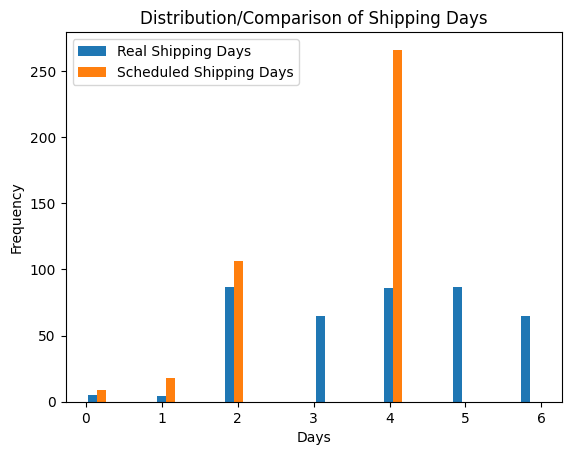

In [53]:
#Days for Shipping Analysis:
#You can create a histogram or box plot to visualize the distribution of
#  "Days for shipping (real)" and "Days for shipment (scheduled)" to understand the typical shipping durations.
import matplotlib.pyplot as plt

# Plotting histograms for days for shipping
plt.hist([Df['Days for shipping (real)'], Df['Days for shipment (scheduled)']], bins=20, label=['Real Shipping Days', 'Scheduled Shipping Days'])
plt.xlabel('Days')
plt.ylabel('Frequency')
plt.title('Distribution/Comparison of Shipping Days')
plt.legend()
plt.show()

In [54]:
Df.columns.tolist()

['Type',
 'Days for shipping (real)',
 'Days for shipment (scheduled)',
 'Benefit per order',
 'Sales per customer',
 'Delivery Status',
 'Late_delivery_risk',
 'Category Id',
 'Category Name',
 'Customer City',
 'Customer Segment',
 'Customer State',
 'Customer Zipcode',
 'Department Id',
 'Department Name',
 'Latitude',
 'Longitude',
 'Market',
 'Order City',
 'Order Country',
 'Order Customer Id',
 'Order Id',
 'Order Item Cardprod Id',
 'Order Item Discount',
 'Order Item Discount Rate',
 'Order Item Id',
 'Order Item Product Price',
 'Order Item Profit Ratio',
 'Order Item Quantity',
 'Sales',
 'Order Item Total',
 'Order Profit Per Order',
 'Order Region',
 'Order State',
 'Order Status',
 'Order Zipcode',
 'Product Card Id',
 'Product Category Id',
 'Product Description',
 'Product Name',
 'Product Price',
 'Product Status',
 'Shipping Mode']

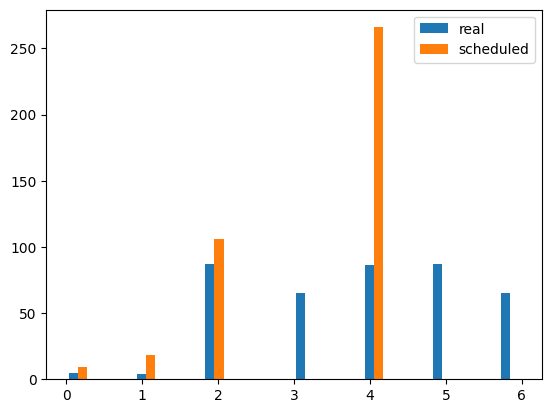

<Axes: xlabel='Delivery Status', ylabel='count'>

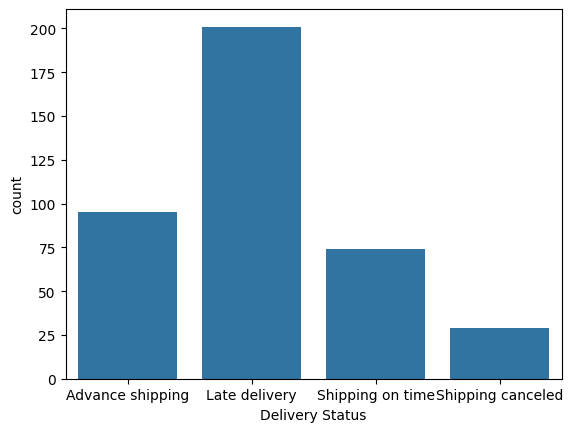

In [55]:
plt.hist([Df['Days for shipping (real)'], Df['Days for shipment (scheduled)']],
bins = 20, label = ['real', 'scheduled'])
plt.legend();plt.show()
sns.countplot(x='Delivery Status', data=Df)

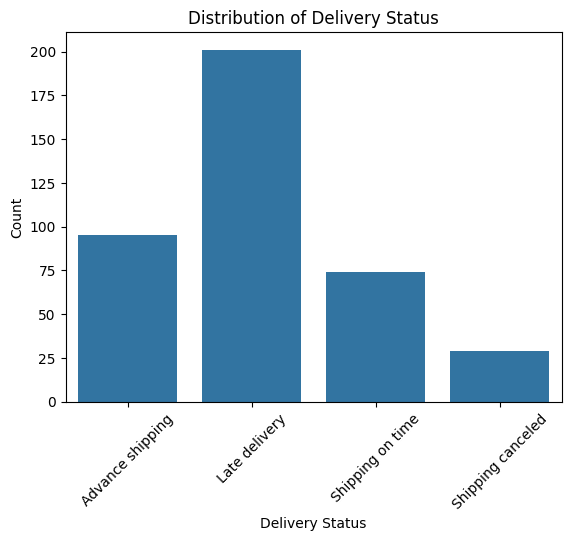

In [56]:
#visualizing delivery status
import seaborn as sns

# Plotting delivery status
sns.countplot(x='Delivery Status', data=Df)
plt.xlabel('Delivery Status')
plt.ylabel('Count')
plt.title('Distribution of Delivery Status')
plt.xticks(rotation=45)
plt.show()


In [57]:
pip install missingno


Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\user\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip



  Using cached missingno-0.5.2-py3-none-any.whl.metadata (639 bytes)


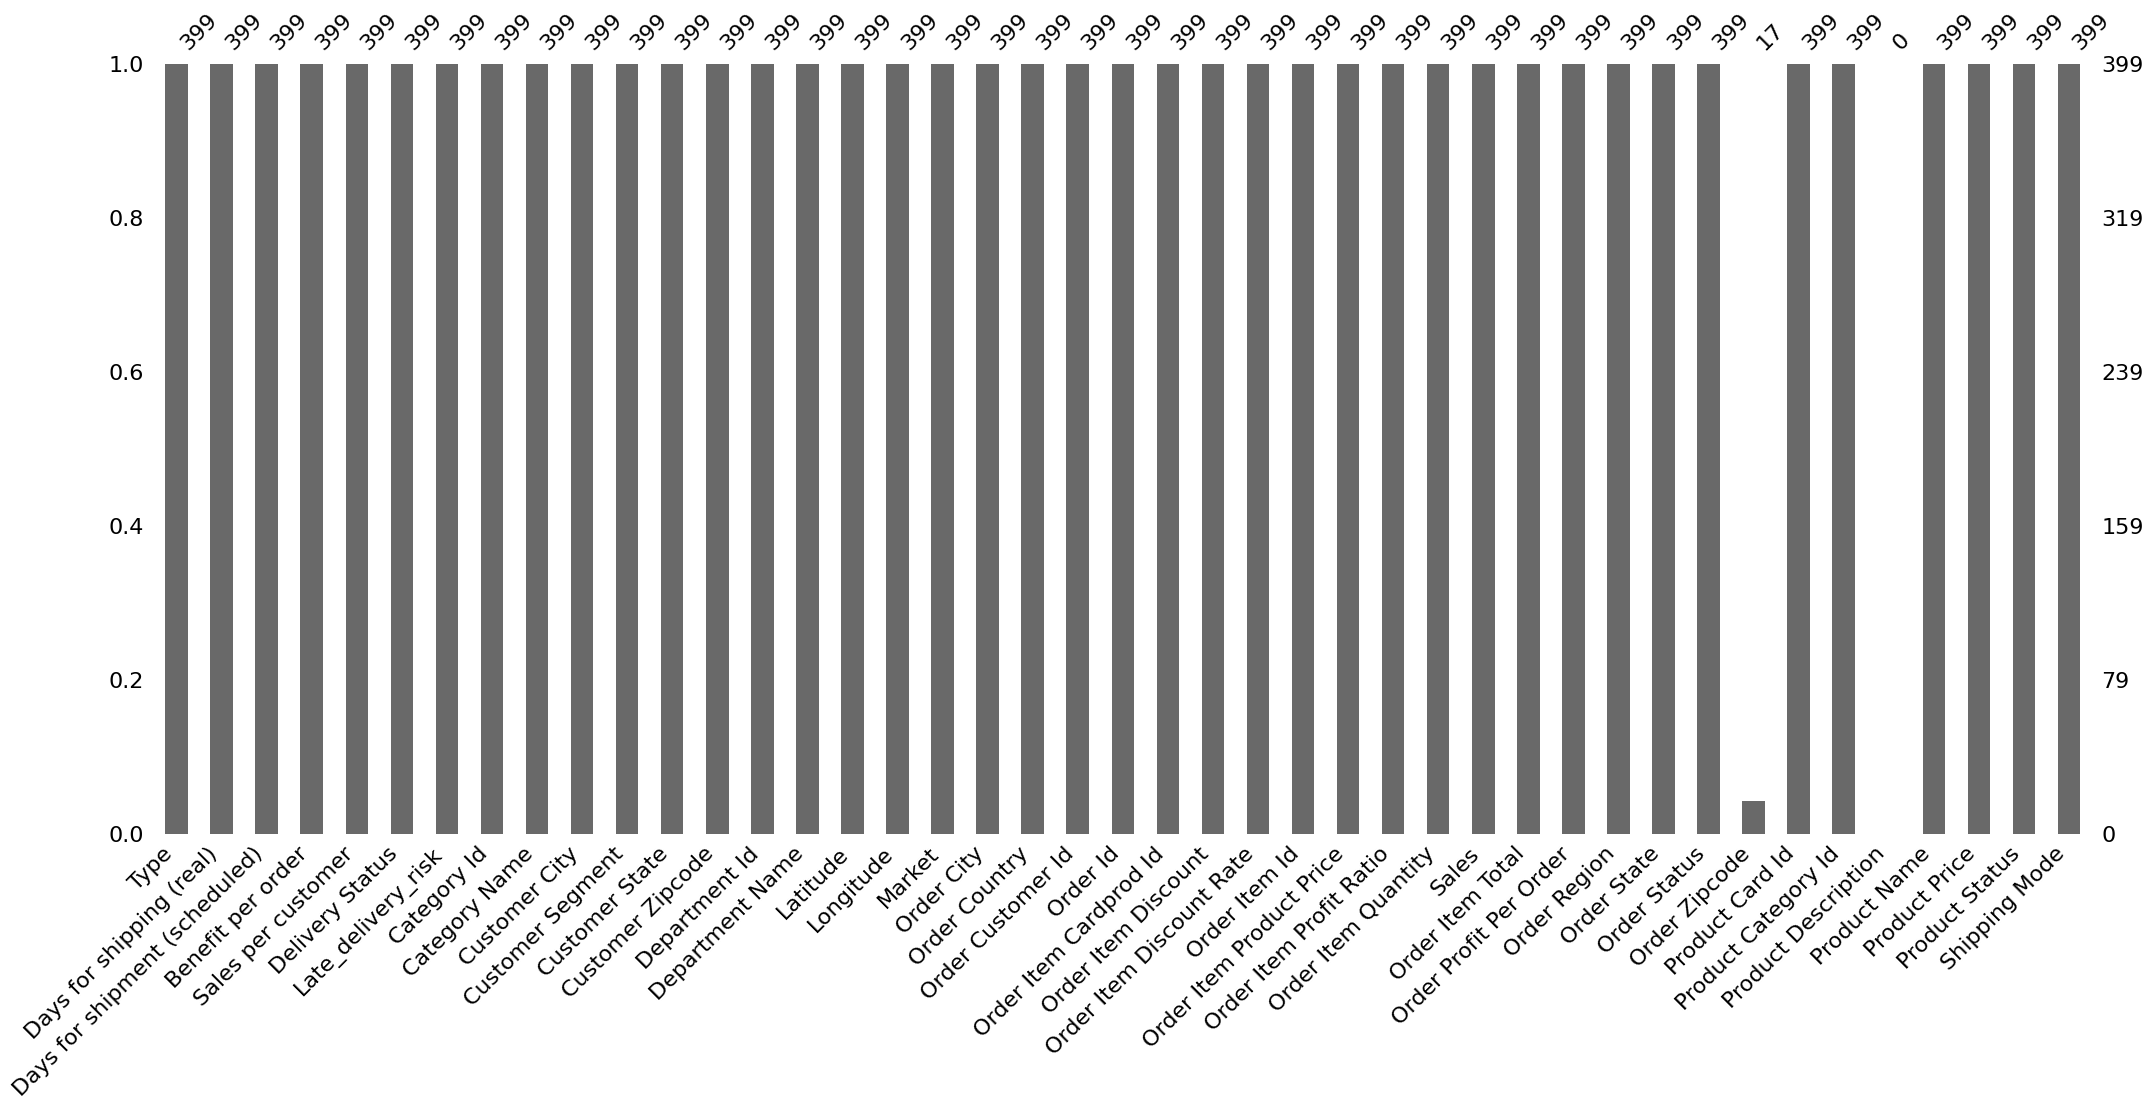

In [58]:
import missingno as msno
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 3))
msno.bar(Df)
plt.show()


In [59]:
Df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 399 entries, 0 to 398
Data columns (total 43 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Type                           399 non-null    object 
 1   Days for shipping (real)       399 non-null    int64  
 2   Days for shipment (scheduled)  399 non-null    int64  
 3   Benefit per order              399 non-null    float64
 4   Sales per customer             399 non-null    float64
 5   Delivery Status                399 non-null    object 
 6   Late_delivery_risk             399 non-null    int64  
 7   Category Id                    399 non-null    int64  
 8   Category Name                  399 non-null    object 
 9   Customer City                  399 non-null    object 
 10  Customer Segment               399 non-null    object 
 11  Customer State                 399 non-null    object 
 12  Customer Zipcode               399 non-null    int

In [60]:
Df = Df.drop(['Order Zipcode','Product Description'],axis =1)

In [61]:
Df.isna().sum()

Type                             0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Benefit per order                0
Sales per customer               0
Delivery Status                  0
Late_delivery_risk               0
Category Id                      0
Category Name                    0
Customer City                    0
Customer Segment                 0
Customer State                   0
Customer Zipcode                 0
Department Id                    0
Department Name                  0
Latitude                         0
Longitude                        0
Market                           0
Order City                       0
Order Country                    0
Order Customer Id                0
Order Id                         0
Order Item Cardprod Id           0
Order Item Discount              0
Order Item Discount Rate         0
Order Item Id                    0
Order Item Product Price         0
Order Item Profit Ratio          0
Order Item Quantity 

In [62]:
Df.dropna(inplace=True)

In [63]:
Df.duplicated().sum()

np.int64(0)

## Scanning the dataFrame

In [64]:
Df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Segment,Customer State,Customer Zipcode,Department Id,...,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Card Id,Product Category Id,Product Name,Product Price,Product Status,Shipping Mode
0,DEBIT,3,4,91.25,314.64,Advance shipping,0,73,Sporting Goods,Caguas,Consumer,PR,725,2,...,0.29,1,327.75,314.64,91.25,Southeast Asia,Java Occidental,COMPLETE,1360,73,Smart watch,327.75,0,Standard Class
1,TRANSFER,5,4,-249.09,311.36,Late delivery,1,73,Sporting Goods,Caguas,Consumer,PR,725,2,...,-0.80,1,327.75,311.36,-249.09,South Asia,Rajastán,PENDING,1360,73,Smart watch,327.75,0,Standard Class
2,CASH,4,4,-247.78,309.72,Shipping on time,0,73,Sporting Goods,San Jose,Consumer,CA,95125,2,...,-0.80,1,327.75,309.72,-247.78,South Asia,Rajastán,CLOSED,1360,73,Smart watch,327.75,0,Standard Class
3,DEBIT,3,4,22.86,304.81,Advance shipping,0,73,Sporting Goods,Los Angeles,Home Office,CA,90027,2,...,0.08,1,327.75,304.81,22.86,Oceania,Queensland,COMPLETE,1360,73,Smart watch,327.75,0,Standard Class
4,PAYMENT,2,4,134.21,298.25,Advance shipping,0,73,Sporting Goods,Caguas,Corporate,PR,725,2,...,0.45,1,327.75,298.25,134.21,Oceania,Queensland,PENDING_PAYMENT,1360,73,Smart watch,327.75,0,Standard Class


In [65]:
#Df.info()

## Data Tranformation - To numerics 

In [66]:
Df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 399 entries, 0 to 398
Data columns (total 41 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Type                           399 non-null    object 
 1   Days for shipping (real)       399 non-null    int64  
 2   Days for shipment (scheduled)  399 non-null    int64  
 3   Benefit per order              399 non-null    float64
 4   Sales per customer             399 non-null    float64
 5   Delivery Status                399 non-null    object 
 6   Late_delivery_risk             399 non-null    int64  
 7   Category Id                    399 non-null    int64  
 8   Category Name                  399 non-null    object 
 9   Customer City                  399 non-null    object 
 10  Customer Segment               399 non-null    object 
 11  Customer State                 399 non-null    object 
 12  Customer Zipcode               399 non-null    int

In [67]:
## Getting Dummy Variables --- 

for col in Df.dtypes[Df.dtypes == 'object'].index:
    for_dummy = Df.pop(col)
    Df = pd.concat([Df,pd.get_dummies(for_dummy, prefix =col)], axis = 1)
Df.head()    

,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Zipcode,Department Id,Latitude,Longitude,Order Customer Id,Order Id,Order Item Cardprod Id,Order Item Discount,...,Product Name_Under Armour Girls' Toddler Spine Surge Runni,Product Name_Under Armour Hustle Storm Medium Duffle Bag,Product Name_Under Armour Kids' Mercenary Slide,Product Name_Under Armour Men's Compression EV SL Slide,Product Name_Under Armour Women's Ignite PIP VI Slide,Product Name_Under Armour Women's Micro G Skulpt Running S,Product Name_Web Camera,Product Name_adidas Men's F10 Messi TRX FG Soccer Cleat,Product Name_adidas Men's Germany Black Crest Away Tee,Product Name_adidas Youth Germany Black/Red Away Match Soc,Shipping Mode_First Class,Shipping Mode_Same Day,Shipping Mode_Second Class,Shipping Mode_Standard Class
0,3,4,91.25,314.64,0,73,725,2,18.25,-66.04,20755,77202,1360,13.11,...,False,False,False,False,False,False,False,False,False,False,False,False,False,True
1,5,4,-249.09,311.36,1,73,725,2,18.28,-66.04,19492,75939,1360,16.39,...,False,False,False,False,False,False,False,False,False,False,False,False,False,True
2,4,4,-247.78,309.72,0,73,95125,2,37.29,-121.88,19491,75938,1360,18.03,...,False,False,False,False,False,False,False,False,False,False,False,False,False,True
3,3,4,22.86,304.81,0,73,90027,2,34.13,-118.29,19490,75937,1360,22.94,...,False,False,False,False,False,False,False,False,False,False,False,False,False,True
4,2,4,134.21,298.25,0,73,725,2,18.25,-66.04,19489,75936,1360,29.50,...,False,False,False,False,False,False,False,False,False,False,False,False,False,True


### Feature Selection 

In [68]:
X = Df.drop(['Days for shipment (scheduled)','Days for shipping (real)'],axis=1)


In [69]:
y = Df [['Days for shipment (scheduled)','Days for shipping (real)']]

In [70]:
X.head()

,Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Zipcode,Department Id,Latitude,Longitude,Order Customer Id,Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,...,Product Name_Under Armour Girls' Toddler Spine Surge Runni,Product Name_Under Armour Hustle Storm Medium Duffle Bag,Product Name_Under Armour Kids' Mercenary Slide,Product Name_Under Armour Men's Compression EV SL Slide,Product Name_Under Armour Women's Ignite PIP VI Slide,Product Name_Under Armour Women's Micro G Skulpt Running S,Product Name_Web Camera,Product Name_adidas Men's F10 Messi TRX FG Soccer Cleat,Product Name_adidas Men's Germany Black Crest Away Tee,Product Name_adidas Youth Germany Black/Red Away Match Soc,Shipping Mode_First Class,Shipping Mode_Same Day,Shipping Mode_Second Class,Shipping Mode_Standard Class
0,91.25,314.64,0,73,725,2,18.25,-66.04,20755,77202,1360,13.11,0.04,180517,...,False,False,False,False,False,False,False,False,False,False,False,False,False,True
1,-249.09,311.36,1,73,725,2,18.28,-66.04,19492,75939,1360,16.39,0.05,179254,...,False,False,False,False,False,False,False,False,False,False,False,False,False,True
2,-247.78,309.72,0,73,95125,2,37.29,-121.88,19491,75938,1360,18.03,0.06,179253,...,False,False,False,False,False,False,False,False,False,False,False,False,False,True
3,22.86,304.81,0,73,90027,2,34.13,-118.29,19490,75937,1360,22.94,0.07,179252,...,False,False,False,False,False,False,False,False,False,False,False,False,False,True
4,134.21,298.25,0,73,725,2,18.25,-66.04,19489,75936,1360,29.50,0.09,179251,...,False,False,False,False,False,False,False,False,False,False,False,False,False,True


## Feature Selection - RFE 

In [71]:
from sklearn.ensemble import RandomForestRegressor ## use for selection of features for random forest regression.
from sklearn.feature_selection import SelectFromModel   ### Incase of a classification problem ,..use -- RandomForestClassifier

In [72]:

# Create a Random Forest Regressor
rf_regressor = RandomForestRegressor(n_estimators=400, random_state=20)  ## used for productivity 

# Train the Random Forest Regressor
rf_regressor.fit(X, y)

# Create feature selector
selector = SelectFromModel(estimator=rf_regressor, threshold='median')
selector.fit(X, y)

# Get selected feature indices
selected_feature_indices = selector.get_support(indices=True)

# Get selected feature names
selected_feature_names = X.columns[selected_feature_indices]

# Sort features by importance scores
feature_importances = rf_regressor.feature_importances_
sorted_indices = feature_importances.argsort()[::-1]

# Define the number of features you want to select
num_features_to_select = 10

# Get top selected feature indices based on the defined number
top_indices = sorted_indices[:num_features_to_select]

# Get top selected feature names
top_feature_names = X.columns[top_indices]

# Print selected feature names
print(f"Top {num_features_to_select} selected features:", top_feature_names)


Top 10 selected features: Index(['Shipping Mode_Standard Class', 'Delivery Status_Advance shipping',
       'Shipping Mode_Second Class', 'Late_delivery_risk',
       'Delivery Status_Late delivery', 'Delivery Status_Shipping on time',
       'Order Customer Id', 'Latitude', 'Order Item Discount',
       'Shipping Mode_First Class'],
      dtype='object')


In [73]:
X = Df[['Shipping Mode_Standard Class', 'Delivery Status_Advance shipping',
       'Shipping Mode_Second Class', 'Late_delivery_risk', 'Order Customer Id',
       'Delivery Status_Late delivery', 'Delivery Status_Shipping on time',
       'Latitude', 'Order Item Discount', 'Shipping Mode_First Class']]

In [74]:
X.shape

(399, 10)

In [75]:
# y

## Splitting data into training and test 

In [76]:
from sklearn.model_selection import train_test_split

In [77]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.30, random_state=10)

In [78]:
X_train.shape

(279, 10)

In [79]:
X_test.shape

(120, 10)

In [80]:
y_train.shape

(279, 2)

In [81]:
y_train.value_counts(normalize = True)

Days for shipment (scheduled)  Days for shipping (real)
4                              5                          0.16
                               4                          0.14
                               2                          0.13
                               3                          0.13
                               6                          0.11
2                              5                          0.07
                               4                          0.07
                               6                          0.06
1                              2                          0.05
2                              2                          0.03
                               3                          0.03
0                              1                          0.01
                               0                          0.01
Name: proportion, dtype: float64

## Fitting the Random Forest Regressor

In [82]:
from sklearn.ensemble import RandomForestRegressor  ## for fiiting random forest regressor
from sklearn.metrics import mean_squared_error

In [83]:
rf = RandomForestRegressor(random_state=40)

In [84]:
rf.fit(X_train,y_train)

RandomForestRegressor(random_state=40)

## Testing the model Performance

In [85]:
y_pred = rf.predict(X_test)

In [86]:
y_pred

array([[4.  , 5.21],
       [4.  , 4.16],
       [4.  , 5.77],
       [4.  , 2.53],
       [2.  , 4.81],
       [4.  , 2.47],
       [2.  , 4.07],
       [4.  , 5.36],
       [2.  , 4.04],
       [4.  , 5.85],
       [4.  , 2.29],
       [2.  , 4.81],
       [4.  , 2.32],
       [4.  , 2.33],
       [1.96, 2.67],
       [4.  , 4.05],
       [2.  , 5.27],
       [2.  , 4.53],
       [4.  , 2.77],
       [4.  , 4.  ],
       [4.  , 4.11],
       [4.  , 2.59],
       [4.  , 2.29],
       [4.  , 2.46],
       [4.  , 5.59],
       [4.  , 5.78],
       [4.  , 4.  ],
       [4.  , 5.31],
       [0.  , 0.23],
       [4.  , 2.82],
       [4.  , 5.31],
       [0.97, 1.97],
       [4.  , 4.92],
       [2.  , 4.8 ],
       [4.  , 5.33],
       [2.  , 2.02],
       [4.  , 2.63],
       [4.  , 5.4 ],
       [2.  , 4.36],
       [2.  , 4.63],
       [2.  , 5.06],
       [4.  , 4.16],
       [2.  , 4.67],
       [0.97, 1.97],
       [4.  , 2.3 ],
       [4.  , 2.76],
       [4.  , 4.13],
       [4.  ,

In [87]:
y_test

,Days for shipment (scheduled),Days for shipping (real)
332,4,6
111,4,4
351,4,6
205,4,2
56,2,5
...,...,...
17,1,2
225,4,5
223,4,3
59,2,2


## Metrics for Comparing Model Evaluation

In [88]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error,mean_squared_log_error,explained_variance_score

In [89]:
# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
mse

0.32917291666666665


An MSE (Mean Squared Error) of 0.3785 indicates that, on average, the squared difference between the actual and predicted values generated by the model is approximately 0.3785. Lower MSE values suggest better model performance, indicating that the model's predictions are closer to the true values. The interpretation of MSE should consider the scale of the target variable, comparison with a baseline model, and potential for model improvement through techniques like feature engineering and hyperparameter tuning.

In [90]:
mean_absolute_error(y_pred, y_test)

0.27612499999999995

In [91]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Assuming y_test and y_pred are your actual and predicted values
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
print("Root Mean Squared Error (RMSE):", rmse)


Root Mean Squared Error (RMSE): 0.5737359293844745


A Mean Absolute Error (MAE) of 6.67 indicates that, on average, the model's predictions deviate from the true values by approximately 6.67 units. Lower MAE values suggest better model accuracy, as they imply closer agreement between predicted and actual values.

In [92]:
r2_score(y_pred, y_test)

0.8116768416219977

In [93]:
# Median Absolute Error (MedAE)
median_absolute_error(y_test, y_pred)


np.float64(0.1875)

In [94]:
# Mean Squared Logarithmic Error (MSLE)
mean_squared_log_error(y_test, y_pred)

0.014861090300389587

In [95]:
# Root Mean Squared Error (RMSE)
np.sqrt(mse)

np.float64(0.5737359293844745)

In [96]:
# Explained Variance Score
explained_variance_score(y_test, y_pred)

0.8468135531823576

In [97]:
param_grid = {
    'n_estimators':[100,200,300],
    'max_depth':[10,20,30],
    'min_samples_split':[2,5,10],
    'min_samples_leaf':[1,2,4]
}

In [98]:
from sklearn.model_selection import GridSearchCV

In [99]:
rfc_cv = GridSearchCV(estimator=rf,
                      param_grid=param_grid,
                      cv=3,
                      scoring='neg_mean_squared_error',  # Specify the scoring metric
                      verbose=2,
                      n_jobs=-1)

In [100]:
# Fit GridSearchCV to the data
rfc_cv.fit(X_train, y_train)


Fitting 3 folds for each of 81 candidates, totalling 243 fits


GridSearchCV(cv=3, estimator=RandomForestRegressor(random_state=40), n_jobs=-1,
             param_grid={'max_depth': [10, 20, 30],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300]},
             scoring='neg_mean_squared_error', verbose=2)

In [101]:
y_pred = rfc_cv.predict(X_test)

In [102]:
mse = mean_squared_error(y_test, y_pred)
mse

0.32653866166082307

In [103]:
r2_score(y_pred, y_test)

0.8121967529400815

In [104]:
# Get the best parameters and best score
best_params = rfc_cv.best_params_
best_score = rfc_cv.best_score_

print("Best Parameters:", best_params)
print("Best Score (Negative MSE):", best_score)

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best Score (Negative MSE): -0.2988148547708139
